
### Two-Stage Pipeline:

1. **Stage 1: Fast CNN Screener**
   - Ultra-lightweight CNN for rapid screening
   - Scans entire signal with sliding window

2. **Stage 2: GNN Validator**
   - Full GNN model for accurate classification
   - Validates screener candidates


---

## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, GAE
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import pyabf
import os
import random
import time

# Reproducibility
SEED = 400
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

#  GPU Setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(" Libraries imported successfully")
print(f"   PyTorch version: {torch.__version__}")
print(f"   CUDA available: {torch.cuda.is_available()}")
print(f"    Using device: {device}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
    print(f"   GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

 Libraries imported successfully
   PyTorch version: 2.5.1+cu118
   CUDA available: True
    Using device: cuda
   GPU: NVIDIA H100
   GPU Memory: 99.96 GB


## Load Training Data

In [ ]:
##############################################
# Data Loading and Preprocessing
##############################################

def interpolate_and_normalize(current_series, target_length=20000):
    """Interpolate and normalize to fixed length"""
    current_series = np.array(current_series)
    original_length = len(current_series)
    x_original = np.linspace(0, 1, original_length)
    x_target = np.linspace(0, 1, target_length)
    wf_interpolated = np.interp(x_target, x_original, current_series)
    wf_mean = wf_interpolated.mean()
    wf_std = wf_interpolated.std() + 1e-6
    wf_normalized = (wf_interpolated - wf_mean) / wf_std
    return wf_normalized, wf_mean, wf_std, original_length

# Load positive samples (real events)
df_events = pd.read_parquet('path/to/your_events.parquet')
df_events['duration_ms'] = df_events['duration'] * 1000
df_events = df_events[(df_events['duration_ms'] > 0) & (df_events['duration_ms'] < 100)]

target_length = 20000

df_events[['waveform_norm', 'wf_mean', 'wf_std', 'orig_length']] = df_events['current_series'].apply(
    lambda cs: pd.Series(interpolate_and_normalize(cs, target_length=target_length))
)

positive_waveforms = np.stack(df_events['waveform_norm'].to_list())
positive_labels = np.ones(len(positive_waveforms))

print(f" Loaded {len(positive_waveforms)} positive samples (real events)")
print(f"   Duration range: {df_events['duration_ms'].min():.2f} - {df_events['duration_ms'].max():.2f} ms")

 Loaded 3426 positive samples (real events)
   Duration range: 0.50 - 53.98 ms


In [3]:
df_events.head()

,event_index,start_time,end_time,duration,amplitude,time_series,current_series,baseline,mean_current,std_current,area,peak_current,max_slope,min_slope,n_points,duration_ms,waveform_norm,wf_mean,wf_std,orig_length
0,1,0.008525,0.021547,0.013022,5.615234,"[0.008525, 0.008525999999999999, 0.008527, 0.0...","[193.81712341308594, 194.12229919433594, 194.8...",193.817123,57.220360,26.604039,0.744985,204.574570,1.529693e+07,-1.927948e+07,13023,13.022,"[5.137787476686822, 5.145261311788379, 5.15707...",57.216683,26.587406,13023
1,2,0.021355,0.023993,0.002638,-6.378173,"[0.021355, 0.021356, 0.021356999999999998, 0.0...","[197.20457458496094, 198.16587829589844, 198.9...",197.204575,71.735962,55.651247,0.189114,204.574570,1.542664e+07,-1.737976e+07,2639,2.638,"[2.2570008347516843, 2.2592810792393347, 2.261...",71.694833,55.609081,2639
2,3,0.135822,0.137057,0.001235,10.360717,"[0.135822, 0.135823, 0.135824, 0.135825, 0.135...","[195.63291931152344, 195.15989685058594, 195.0...",195.632919,99.980701,68.179718,0.123380,204.620346,1.445007e+07,-1.844024e+07,1236,1.235,"[1.4046731628823421, 1.404244527344429, 1.4038...",99.907440,68.147867,1236
3,4,0.224859,0.226588,0.001729,32.562252,"[0.224859, 0.22485999999999998, 0.224860999999...","[199.78330993652344, 199.35606384277344, 198.8...",199.783310,85.767397,61.376181,0.148180,204.421982,1.883698e+07,-1.839447e+07,1730,1.729,"[1.8599600268756773, 1.859357776555494, 1.8587...",85.708072,61.332091,1730
4,5,0.324631,0.325557,0.000926,-2.120971,"[0.324631, 0.324632, 0.324633, 0.324634, 0.324...","[196.04490661621094, 196.10594177246094, 195.8...",196.044907,128.174690,61.664553,0.118622,202.301010,1.347351e+07,-2.040863e+07,927,0.926,"[1.1020148699036367, 1.1020607101045816, 1.102...",128.105193,61.650450,927


## Negative Sample Generation

In [ ]:
##############################################
# Generate Negative Samples
##############################################

def generate_negative_samples(abf_file, num_samples, target_length=20000, 
                             min_duration_samples=None, max_duration_samples=None):
    """Generate negative samples from baseline regions"""
    abf = pyabf.ABF(abf_file)
    
    all_sweeps = []
    for sweep in range(min(10, abf.sweepCount)):
        abf.setSweep(sweep)
        all_sweeps.append(abf.sweepY)
    raw_signal = np.concatenate(all_sweeps)
    
    baseline = np.median(raw_signal)
    std = np.std(raw_signal)
    is_baseline = np.abs(raw_signal - baseline) < 0.5 * std
    
    baseline_padded = np.concatenate([[False], is_baseline, [False]])
    transitions = np.diff(baseline_padded.astype(int))
    baseline_starts = np.where(transitions == 1)[0]
    baseline_ends = np.where(transitions == -1)[0]
    
    if min_duration_samples is None:
        min_duration_samples = int(0.5 * abf.dataRate / 1000)
    if max_duration_samples is None:
        max_duration_samples = int(30.0 * abf.dataRate / 1000)
    
    baseline_regions = [(s, e) for s, e in zip(baseline_starts, baseline_ends) 
                        if e - s >= max_duration_samples]
    
    negative_samples = []
    for _ in range(num_samples):
        if len(baseline_regions) == 0:
            start = np.random.randint(0, len(raw_signal) - max_duration_samples)
            duration = np.random.randint(min_duration_samples, max_duration_samples)
        else:
            region_start, region_end = baseline_regions[np.random.randint(0, len(baseline_regions))]
            max_start = region_end - max_duration_samples
            if max_start <= region_start:
                max_start = region_start + 1
            start = np.random.randint(region_start, max_start)
            duration = np.random.randint(min_duration_samples, 
                                        min(max_duration_samples, region_end - start))
        
        window = raw_signal[start:start+duration]
        normalized, wf_mean, wf_std, orig_length = interpolate_and_normalize(window, target_length)
        negative_samples.append(normalized)
    
    return np.array(negative_samples)

negative_waveforms = generate_negative_samples(
    abf_file='path/to/your_recording.abf',
    num_samples=len(positive_waveforms),
    target_length=target_length
)
negative_labels = np.zeros(len(negative_waveforms))

print(f" Generated {len(negative_waveforms)} negative samples")

 Generated 3426 negative samples


## Dataset Assembly and Splits

In [5]:
##############################################
# Combine and Split Dataset
##############################################

all_waveforms = np.concatenate([positive_waveforms, negative_waveforms])
all_labels = np.concatenate([positive_labels, negative_labels])

# Shuffle
indices = np.random.permutation(len(all_waveforms))
all_waveforms = all_waveforms[indices]
all_labels = all_labels[indices]

# Split
train_wf, temp_wf, train_labels, temp_labels = train_test_split(
    all_waveforms, all_labels, test_size=0.3, random_state=SEED, stratify=all_labels
)

val_wf, test_wf, val_labels, test_labels = train_test_split(
    temp_wf, temp_labels, test_size=0.33, random_state=SEED, stratify=temp_labels
)

# Convert to tensors and move to GPU
train_tensor = torch.tensor(train_wf, dtype=torch.float32).unsqueeze(1).to(device)
val_tensor = torch.tensor(val_wf, dtype=torch.float32).unsqueeze(1).to(device)
test_tensor = torch.tensor(test_wf, dtype=torch.float32).unsqueeze(1).to(device)

train_labels_tensor = torch.tensor(train_labels, dtype=torch.float32).to(device)
val_labels_tensor = torch.tensor(val_labels, dtype=torch.float32).to(device)
test_labels_tensor = torch.tensor(test_labels, dtype=torch.float32).to(device)

print(f"\n Dataset Split:")
print(f"   Train: {len(train_wf)} ({train_labels.sum():.0f} events, {(train_labels==0).sum():.0f} non-events)")
print(f"   Val:   {len(val_wf)} ({val_labels.sum():.0f} events, {(val_labels==0).sum():.0f} non-events)")
print(f"   Test:  {len(test_wf)} ({test_labels.sum():.0f} events, {(test_labels==0).sum():.0f} non-events)")
print(f"    Tensors on: {device}")


 Dataset Split:
   Train: 4796 (2398 events, 2398 non-events)
   Val:   1377 (689 events, 688 non-events)
   Test:  679 (339 events, 340 non-events)
    Tensors on: cuda


## Stage 1: Fast CNN Screener Architecture


In [6]:
##############################################
# Stage 1: Fast CNN Screener
##############################################

class FastEventScreener(nn.Module):
    """Ultra-lightweight CNN for quick event screening"""
    def __init__(self, target_length=20000):
        super().__init__()
        self.target_length = target_length
        self.conv1 = nn.Conv1d(1, 16, kernel_size=5, padding=2)
        self.pool = nn.MaxPool1d(4)
        self.conv2 = nn.Conv1d(16, 32, kernel_size=3, padding=1)
        
        # Calculate feature size after pooling
        # 10000 -> pool(4) -> 2500 -> pool(4) -> 625
        self.fc = nn.Linear(32 * (target_length // 16), 1)
        
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(x)
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        return torch.sigmoid(self.fc(x))

# Initialize
screener = FastEventScreener(target_length=target_length)
print(f" Fast Screener initialized")
print(f"   Parameters: {sum(p.numel() for p in screener.parameters()):,}")
print(f"   (vs ~20M in full GNN model)")

 Fast Screener initialized
   Parameters: 41,665
   (vs ~20M in full GNN model)


### Train Fast Screener

In [7]:
##############################################
# Train Screener Model
##############################################

def train_screener(train_tensor, train_labels, val_tensor, val_labels, 
                   num_epochs=50, learning_rate=0.001):
    """
    Train the fast screener on same data as GNN.
    
    Goal: High recall (catch all events), even if precision is lower.
    """
    screener = FastEventScreener(target_length=train_tensor.shape[-1]).to(device)
    optimizer = optim.Adam(screener.parameters(), lr=learning_rate)
    criterion = nn.BCELoss()
    
    train_losses = []
    val_losses = []
    val_recalls = []
    best_val_loss = float('inf')
    
    print(f"\n🏋️ Training Fast Screener for {num_epochs} epochs...")
    print(f"   🚀 Training on: {device}")
    
    for epoch in range(1, num_epochs + 1):
        # Training
        screener.train()
        optimizer.zero_grad()
        
        probs = screener(train_tensor).squeeze()
        loss = criterion(probs, train_labels)
        
        loss.backward()
        optimizer.step()
        
        train_losses.append(loss.item())
        
        # Validation
        screener.eval()
        with torch.no_grad():
            val_probs = screener(val_tensor).squeeze()
            val_loss = criterion(val_probs, val_labels)
            
            # Compute recall (most important for screener)
            val_preds = (val_probs > 0.3).float()  # Low threshold for high recall
            true_positives = ((val_preds == 1) & (val_labels == 1)).sum().item()
            actual_positives = (val_labels == 1).sum().item()
            recall = true_positives / actual_positives if actual_positives > 0 else 0
        
        val_losses.append(val_loss.item())
        val_recalls.append(recall)
        
        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(screener.state_dict(), 'fast_screener.pth')
        
        if epoch % 10 == 0 or epoch == 1:
            print(f"Epoch {epoch:3d}/{num_epochs} | "
                  f"Train Loss: {loss.item():.4f} | "
                  f"Val Loss: {val_loss.item():.4f} | "
                  f"Val Recall: {recall:.3f}")
    
    print(f"\n Screener training complete!")
    print(f"   Best validation loss: {best_val_loss:.4f}")
    print(f"   Final recall: {val_recalls[-1]:.3f}")
    
    # Load best model
    screener.load_state_dict(torch.load('fast_screener.pth', map_location=device, weights_only=True))
    
    return screener, train_losses, val_losses, val_recalls

# Train the screener
print("="*70)
print("TRAINING FAST EVENT SCREENER")
print("="*70)
screener, train_losses, val_losses, val_recalls = train_screener(
    train_tensor, train_labels_tensor, 
    val_tensor, val_labels_tensor,
    num_epochs=550, learning_rate=0.005
)

TRAINING FAST EVENT SCREENER

🏋️ Training Fast Screener for 550 epochs...
   🚀 Training on: cuda
Epoch   1/550 | Train Loss: 0.6648 | Val Loss: 7.1702 | Val Recall: 0.000
Epoch  10/550 | Train Loss: 0.2759 | Val Loss: 0.2073 | Val Recall: 0.923
Epoch  20/550 | Train Loss: 0.0860 | Val Loss: 0.0767 | Val Recall: 0.994
Epoch  30/550 | Train Loss: 0.0411 | Val Loss: 0.0484 | Val Recall: 0.980
Epoch  40/550 | Train Loss: 0.0394 | Val Loss: 0.0493 | Val Recall: 0.977
Epoch  50/550 | Train Loss: 0.0340 | Val Loss: 0.0444 | Val Recall: 0.980
Epoch  60/550 | Train Loss: 0.0295 | Val Loss: 0.0409 | Val Recall: 0.981
Epoch  70/550 | Train Loss: 0.0262 | Val Loss: 0.0387 | Val Recall: 0.983
Epoch  80/550 | Train Loss: 0.0232 | Val Loss: 0.0376 | Val Recall: 0.981
Epoch  90/550 | Train Loss: 0.0201 | Val Loss: 0.0366 | Val Recall: 0.983
Epoch 100/550 | Train Loss: 0.0170 | Val Loss: 0.0359 | Val Recall: 0.984
Epoch 110/550 | Train Loss: 0.0143 | Val Loss: 0.0373 | Val Recall: 0.983
Epoch 120/550 |

###  Screener Training Curves

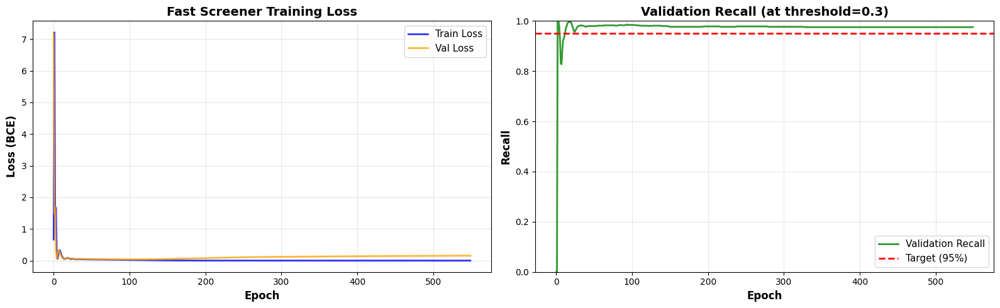

In [8]:
##############################################
# Plot Screener Training History
##############################################

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Loss plot
axes[0].plot(train_losses, label='Train Loss', linewidth=2, alpha=0.8, color='blue')
axes[0].plot(val_losses, label='Val Loss', linewidth=2, alpha=0.8, color='orange')
axes[0].set_xlabel('Epoch', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Loss (BCE)', fontsize=12, fontweight='bold')
axes[0].set_title('Fast Screener Training Loss', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Recall plot
axes[1].plot(val_recalls, label='Validation Recall', linewidth=2, alpha=0.8, color='green')
axes[1].axhline(0.95, color='red', linestyle='--', linewidth=2, label='Target (95%)')
axes[1].set_xlabel('Epoch', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Recall', fontsize=12, fontweight='bold')
axes[1].set_title('Validation Recall (at threshold=0.3)', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

## Evaluate Screener Performance

In [9]:
##############################################
# Evaluate Screener Performance
##############################################

print("\n" + "="*70)
print("SCREENER PERFORMANCE EVALUATION")
print("="*70)

screener.eval()
with torch.no_grad():
    test_screener_probs = screener(test_tensor).squeeze()

# Test at different thresholds
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]
print("\nScreener Performance at Different Thresholds:")
print(f"{'Threshold':<12} {'Recall':<10} {'Precision':<12} {'F1 Score':<10}")
print("-" * 50)


for thresh in thresholds:
    preds = (test_screener_probs > thresh).float()
    
    tp = ((preds == 1) & (test_labels_tensor == 1)).sum().item()
    fp = ((preds == 1) & (test_labels_tensor == 0)).sum().item()
    fn = ((preds == 0) & (test_labels_tensor == 1)).sum().item()
    
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    print(f"{thresh:<12.2f} {recall:<10.3f} {precision:<12.3f} {f1:<10.3f}")


SCREENER PERFORMANCE EVALUATION

Screener Performance at Different Thresholds:
Threshold    Recall     Precision    F1 Score  
--------------------------------------------------
0.10         0.997      0.947        0.971     
0.20         0.994      0.971        0.983     
0.30         0.988      0.974        0.981     
0.40         0.988      0.985        0.987     
0.50         0.988      0.997        0.993     


##  Stage 2: GAE Training on Screened Events

Now we'll train a Graph Autoencoder (GAE) **only on the detected events** from Stage 1.

### Architecture:
1. **CNN Encoder**: Extract initial features from waveforms
2. **KNN Graph Builder**: Build graph based on feature similarity
3. **GCN Encoder**: Graph-aware latent representations
4. **CNN Decoder**: Reconstruct waveforms from latent space



In [10]:
##############################################
# Extract Screened Event Candidates
##############################################

# Use the trained screener to identify event candidates
# We'll use a low threshold to ensure high recall
SCREENER_THRESHOLD = 0.4

print("="*70)
print("EXTRACTING EVENT CANDIDATES FROM STAGE 1")
print("="*70)

screener.eval()
with torch.no_grad():
    # Get predictions on positive samples (real events)
    positive_probs = screener(torch.tensor(positive_waveforms, dtype=torch.float32).unsqueeze(1).to(device)).squeeze()
    
    # Filter events based on screener threshold
    event_mask = positive_probs.cpu().numpy() > SCREENER_THRESHOLD
    screened_events = positive_waveforms[event_mask]
    
    print(f"\n  Stage 1 Screening Results:")
    print(f"   Input events: {len(positive_waveforms)}")
    print(f"   Screened events: {len(screened_events)} ({len(screened_events)/len(positive_waveforms)*100:.1f}%)")
    print(f"   Filtered out: {(~event_mask).sum()} ({(~event_mask).sum()/len(positive_waveforms)*100:.1f}%)")

# Convert to tensor for GAE training
screened_events_tensor = torch.tensor(screened_events, dtype=torch.float32).unsqueeze(1).to(device)

print(f"\n  Screened events ready for GAE training")
print(f"   Shape: {screened_events_tensor.shape}")
print(f"   Device: {screened_events_tensor.device}")

EXTRACTING EVENT CANDIDATES FROM STAGE 1

  Stage 1 Screening Results:
   Input events: 3426
   Screened events: 3397 (99.2%)
   Filtered out: 29 (0.8%)

  Screened events ready for GAE training
   Shape: torch.Size([3397, 1, 20000])
   Device: cuda:0


## Building the Similarity Graph


In [11]:
##############################################
# GAE Architecture Components
##############################################

# CNN Encoder for initial feature extraction
class WaveformEncoder(nn.Module):
    def __init__(self, in_channels=1, out_features=128, target_length=20000):
        super(WaveformEncoder, self).__init__()
        self.conv1 = nn.Conv1d(in_channels, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(32, 64, kernel_size=3, padding=1)
        # Compute the flattened size after two pooling layers
        self.fc = nn.Linear(64 * (target_length // 4), out_features)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(x)
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


# GAE encoder using GCN layers
class EncoderGAE(nn.Module):
    def __init__(self, in_channels, hidden_channels):
        super(EncoderGAE, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        return self.conv2(x, edge_index)


# CNN-based Decoder to reconstruct waveforms
class WaveformDecoder(nn.Module):
    def __init__(self, latent_dim, target_length=20000):
        super(WaveformDecoder, self).__init__()
        self.target_length = target_length
        self.feature_map_length = target_length // 4  # after two poolings
        self.fc = nn.Linear(latent_dim, 64 * self.feature_map_length)
        self.upsample = nn.Upsample(scale_factor=2, mode='linear', align_corners=True)
        self.conv1 = nn.Conv1d(64, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(32, 1, kernel_size=3, padding=1)

    def forward(self, z):
        x = self.fc(z)
        x = x.view(-1, 64, self.feature_map_length)
        x = self.upsample(x)  # upsample to target_length//2
        x = F.relu(self.conv1(x))
        x = self.upsample(x)  # upsample to target_length
        x = self.conv2(x)
        return x  # (batch_size, 1, target_length)


# Joint model combines CNN encoder, GAE, and decoder
class JointModelWithDecoder(nn.Module):
    def __init__(self, encoder, gae, decoder):
        super(JointModelWithDecoder, self).__init__()
        self.encoder = encoder      # Extract latent features from waveforms
        self.gae = gae              # Graph autoencoder module
        self.decoder = decoder      # Reconstruct the waveform from latent space

    def forward(self, waveform_tensor, edge_index):
        x = self.encoder(waveform_tensor)          # CNN latent features
        z = self.gae.encode(x, edge_index)         # Graph-aware latent representation
        reconstructed_waveform = self.decoder(z)   # Reconstruction from latent space
        return z, reconstructed_waveform

    def graph_recon_loss(self, z, pos_edge_index, neg_edge_index):
        """Graph reconstruction loss using cosine similarity"""
        pos_sim = F.cosine_similarity(z[pos_edge_index[0]], z[pos_edge_index[1]])
        neg_sim = F.cosine_similarity(z[neg_edge_index[0]], z[neg_edge_index[1]])
        pos_loss = -torch.log(torch.sigmoid(pos_sim) + 1e-15).mean()
        neg_loss = -torch.log(1 - torch.sigmoid(neg_sim) + 1e-15).mean()
        return pos_loss + neg_loss

    def waveform_recon_loss(self, original_waveforms, reconstructed_waveforms):
        """Waveform reconstruction loss (MSE)"""
        return F.mse_loss(reconstructed_waveforms, original_waveforms)

print("  GAE architecture components defined:")
print("   - WaveformEncoder (CNN)")
print("   - EncoderGAE (GCN)")
print("   - WaveformDecoder (CNN)")
print("   - JointModelWithDecoder (Combined)")

  GAE architecture components defined:
   - WaveformEncoder (CNN)
   - EncoderGAE (GCN)
   - WaveformDecoder (CNN)
   - JointModelWithDecoder (Combined)


In [12]:
##############################################
# Build KNN Graph from CNN Encodings
##############################################

def build_knn_graph(embeddings, k=5):
    """Build k-nearest neighbor graph based on cosine similarity"""
    norm_embeddings = F.normalize(embeddings, p=2, dim=1)
    sim_matrix = torch.mm(norm_embeddings, norm_embeddings.t())
    num_nodes = embeddings.size(0)
    edge_index_list = []
    
    for i in range(num_nodes):
        sim_row = sim_matrix[i].clone()
        sim_row[i] = -1.0  # Exclude self-connection
        topk = torch.topk(sim_row, k).indices
        for j in topk:
            edge_index_list.append([i, int(j)])
            edge_index_list.append([int(j), i])  # Undirected graph
    
    edge_index = torch.tensor(edge_index_list, dtype=torch.long, device=embeddings.device).t().contiguous()
    return edge_index  # device of input embeddings

print("KNN graph builder defined")
print("Will construct graph based on feature similarity")

KNN graph builder defined
Will construct graph based on feature similarity


### GAE Data Setup

We prepare inputs for graph autoencoding:
- Use CNN embeddings to initialize a KNN graph.
- Wrap waveforms and edges in a `torch_geometric.data.Data` object.
- Apply `RandomLinkSplit` to create train/val/test edge sets for link prediction.

In [13]:
##############################################
# Prepare Data for GAE Training
##############################################

from torch_geometric.data import Data
from torch_geometric.transforms import RandomLinkSplit

# Initialize temporary encoder to build initial graph
latent_dim = 128
temp_encoder = WaveformEncoder(in_channels=1, out_features=latent_dim, target_length=target_length).to(device)

# Build initial embeddings
with torch.no_grad():
    init_embeddings = temp_encoder(screened_events_tensor)

# Build KNN graph
print(f"\n Building KNN graph...")
edge_index = build_knn_graph(init_embeddings, k=5)

print(f"   Nodes: {screened_events_tensor.shape[0]}")
print(f"   Edges: {edge_index.shape[1]}")
print(f"   Avg degree: {edge_index.shape[1] / screened_events_tensor.shape[0]:.1f}")

# Create PyTorch Geometric Data object
data = Data(x=screened_events_tensor, edge_index=edge_index.to(device))

# Split into train/val/test for link prediction
transform = RandomLinkSplit(num_val=0.2, num_test=0.1, is_undirected=True, split_labels=True)
train_data, val_data, test_data = transform(data)

print(f"\n Data split for GAE:")
print(f"   Train edges: {train_data.pos_edge_label_index.shape[1]}")
print(f"   Val edges: {val_data.pos_edge_label_index.shape[1]}")
print(f"   Test edges: {test_data.pos_edge_label_index.shape[1]}")
print(f"   Data on: {device}")


 Building KNN graph...
   Nodes: 3397
   Edges: 33970
   Avg degree: 10.0

 Data split for GAE:
   Train edges: 11890
   Val edges: 3397
   Test edges: 1698
   Data on: cuda


### Initialize GAE Components

We define and instantiate the model parts:
- `WaveformEncoder` (CNN) → per-event features.
- `EncoderGAE` (GCN) wrapped in `GAE` → graph-aware latent space.
- `WaveformDecoder` (CNN) → reconstruct original waveforms.

We also log parameter counts and device placement.

### Visualise Embeddings

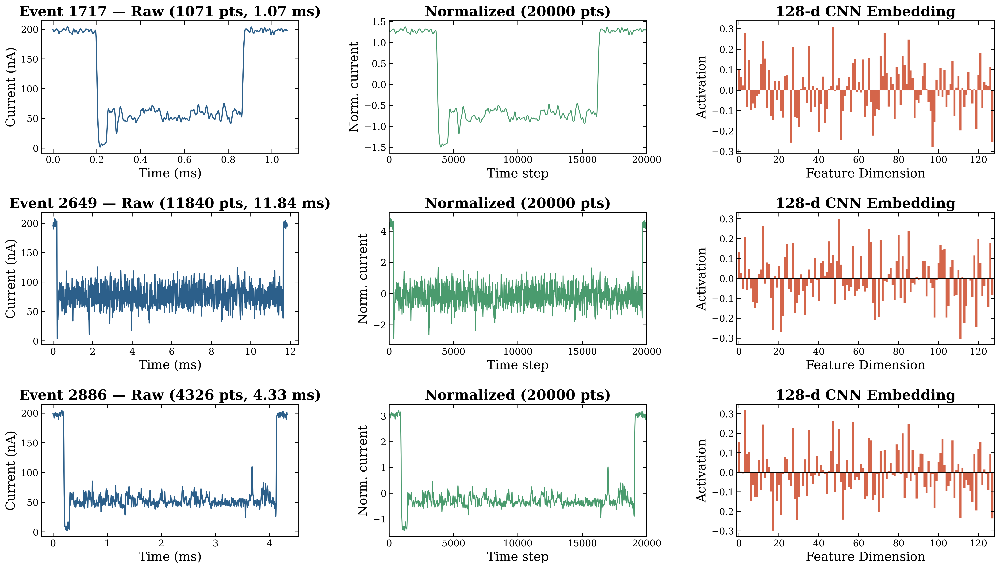

Embedding shape: (3397, 128)


In [14]:
##############################################
# Visualize Raw → Normalized → CNN Embedding
##############################################

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.size': 16, 'axes.titlesize': 18, 'axes.labelsize': 16,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'figure.dpi': 350,
    'savefig.dpi': 300, 'font.family': 'serif', 'axes.linewidth': 1.2,
    'xtick.major.width': 1.0, 'ytick.major.width': 1.0,
    'xtick.major.size': 5, 'ytick.major.size': 5,
    'xtick.direction': 'in', 'ytick.direction': 'in',
})

embeddings_np = init_embeddings.detach().cpu().numpy()

num_samples = 3
np.random.seed(SEED)
screened_df = df_events[event_mask].reset_index(drop=True)
screened_durations = screened_df['duration_ms'].values
sample_indices = np.random.choice(len(screened_events), num_samples, replace=False)

fig, axs = plt.subplots(num_samples, 3, figsize=(22, 4 * num_samples),
                         gridspec_kw={'wspace': 0.35, 'hspace': 0.45})

for i, idx in enumerate(sample_indices):
    event = screened_df.iloc[idx]
    raw_current = np.array(event['current_series'])
    duration_ms = event['duration_ms']
    t_ms = np.linspace(0, duration_ms, len(raw_current))

    # Col 0: Raw event in real time
    axs[i, 0].plot(t_ms, raw_current, color='#2C5F8A', linewidth=1.5)
    axs[i, 0].set_title(f'Event {idx} — Raw ({len(raw_current)} pts, {duration_ms:.2f} ms)', fontweight='bold')
    axs[i, 0].set_xlabel('Time (ms)')
    axs[i, 0].set_ylabel('Current (nA)')
    axs[i, 0].tick_params(which='both', top=True, right=True)

    # Col 1: Normalized waveform in time steps
    axs[i, 1].plot(np.arange(len(screened_events[idx])), screened_events[idx],
                    color='#4A9B6E', linewidth=1.2)
    axs[i, 1].set_title(f'Normalized ({target_length} pts)', fontweight='bold')
    axs[i, 1].set_xlabel('Time step')
    axs[i, 1].set_ylabel('Norm. current')
    axs[i, 1].set_xticks(np.arange(0, target_length + 1, 5000))
    axs[i, 1].set_xlim(0, target_length)
    axs[i, 1].tick_params(which='both', top=True, right=True)


    # Col 2: 128-d CNN embedding
    axs[i, 2].bar(np.arange(embeddings_np.shape[1]), embeddings_np[idx],
                   color='#D4654A', width=1.0, edgecolor='none')
    axs[i, 2].set_title('128-d CNN Embedding', fontweight='bold')
    axs[i, 2].set_xlabel('Feature Dimension')
    axs[i, 2].set_ylabel('Activation')
    axs[i, 2].axhline(y=0, color='k', linewidth=0.6, linestyle='-')
    axs[i, 2].set_xlim(-1, embeddings_np.shape[1])
    axs[i, 2].tick_params(which='both', top=True, right=True)

plt.show()

print(f"Embedding shape: {embeddings_np.shape}")


In [15]:
##############################################
# Initialize GAE Model
##############################################

# Create model components
encoder = WaveformEncoder(in_channels=1, out_features=latent_dim, target_length=target_length).to(device)
gae_model = GAE(EncoderGAE(in_channels=latent_dim, hidden_channels=latent_dim)).to(device)
decoder = WaveformDecoder(latent_dim=latent_dim, target_length=target_length).to(device)

# Combine into joint model
joint_model = JointModelWithDecoder(encoder, gae_model, decoder).to(device)

# Count parameters
total_params = sum(p.numel() for p in joint_model.parameters())
print(f"GAE Model initialized")
print(f"   Total parameters: {total_params:,}")
print(f"   Latent dimension: {latent_dim}")
print(f"    Model on: {device}")

GAE Model initialized
   Total parameters: 82,285,761
   Latent dimension: 128
    Model on: cuda


### Visualise the Graph

/tmp/zz342074/login23-g-1_511059/ipykernel_60677/306183267.py:63: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0].legend(loc='lower right', fontsize=10, framealpha=0.9)


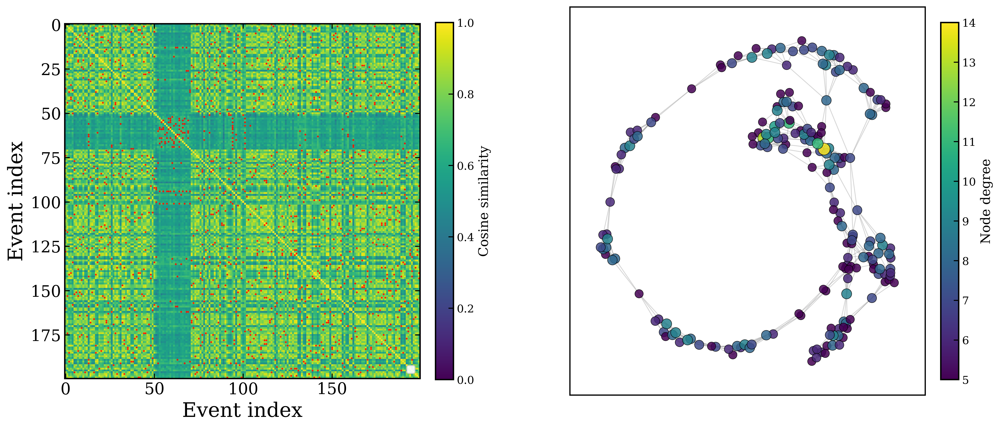

Nodes: 200, Edges: 670
Avg degree: 6.7
k-NN edges overlaid on heatmap: 1340


In [16]:
##############################################
# Visualize Similarity Matrix & k-NN Graph
##############################################

import matplotlib.pyplot as plt
import networkx as nx
from torch_geometric.utils import to_networkx
import torch.nn.functional as F

plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'figure.dpi': 350,
    'savefig.dpi': 350,
    'font.family': 'serif',
    'axes.linewidth': 1.4,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
})

num_plot = 200

# Slice first N embeddings
emb_sub = init_embeddings[:num_plot]

# Cosine similarity matrix
norm_emb = F.normalize(emb_sub, p=2, dim=1)
sim_matrix = torch.mm(norm_emb, norm_emb.t()).cpu().numpy()

# k-NN graph on the subset
edge_index_sub = build_knn_graph(emb_sub, k=5)

# Build adjacency mask for edge overlay
adj = np.zeros((num_plot, num_plot), dtype=bool)
src, dst = edge_index_sub.cpu().numpy()
edge_mask = (src < num_plot) & (dst < num_plot)
for s, d in zip(src[edge_mask], dst[edge_mask]):
    adj[s, d] = True
edge_rows, edge_cols = np.where(adj)

# NetworkX graph for panel b
data_sub = Data(x=emb_sub, edge_index=edge_index_sub)
G = to_networkx(data_sub, to_undirected=True)

fig, axs = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'wspace': 0.3})

# --- a) Similarity heatmap with edge markers ---
im = axs[0].imshow(sim_matrix, vmin=0.0, vmax=1.0, cmap='viridis', interpolation='nearest')
axs[0].scatter(edge_cols, edge_rows, s=3, color='red', marker='.', alpha=0.8)#, label='k-NN edge')
cbar = fig.colorbar(im, ax=axs[0], fraction=0.046, pad=0.04)
cbar.set_label('Cosine similarity', fontsize=13)
cbar.ax.tick_params(labelsize=11)
#axs[0].set_title(f'Pairwise Cosine Similarity ({num_plot} Events)', fontweight='bold')
axs[0].set_xlabel('Event index')
axs[0].set_ylabel('Event index')
axs[0].legend(loc='lower right', fontsize=10, framealpha=0.9)
axs[0].tick_params(which='both', top=True, right=True)
#axs[0].annotate('a)', xy=(0.02, 0.95), xycoords='axes fraction',
#                fontsize=16, fontweight='bold', color='white')

# --- b) k-NN graph ---
pos = nx.spring_layout(G, seed=123, k=0.15, iterations=80)
degrees = dict(G.degree())
node_sizes = [30 + 8 * degrees[n] for n in G.nodes()]

nx.draw_networkx_edges(G, pos, ax=axs[1], edge_color='#999999', alpha=0.4, width=0.8)
nx.draw_networkx_nodes(G, pos, ax=axs[1], node_size=node_sizes,
                       node_color=list(degrees.values()), cmap='viridis',
                       edgecolors='black', linewidths=0.5, alpha=0.85)

sm = plt.cm.ScalarMappable(cmap='viridis',
        norm=plt.Normalize(vmin=min(degrees.values()), vmax=max(degrees.values())))
sm.set_array([])
cbar2 = fig.colorbar(sm, ax=axs[1], fraction=0.046, pad=0.04)
cbar2.set_label('Node degree', fontsize=13)
cbar2.ax.tick_params(labelsize=11)

#axs[1].set_title(f'$k$-NN Graph ($k$=5, {num_plot} Events)', fontweight='bold')
axs[1].set_axis_on()
axs[1].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
for spine in axs[1].spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)
#axs[1].annotate('b)', xy=(0.02, 0.95), xycoords='axes fraction',
#                fontsize=16, fontweight='bold', color='black')

#plt.savefig('similarity_and_knn_graph.pdf', bbox_inches='tight', pad_inches=0.1)
#plt.savefig('similarity_and_knn_graph.png', bbox_inches='tight', pad_inches=0.1)
plt.show()

print(f"Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}")
print(f"Avg degree: {2 * G.number_of_edges() / G.number_of_nodes():.1f}")
print(f"k-NN edges overlaid on heatmap: {len(edge_rows)}")


### Training Strategy for GAE

We jointly optimize two objectives per epoch:
- Graph reconstruction (link prediction via cosine-similarity logistic loss).
- Waveform reconstruction (MSE between original and decoded waveforms).


In [17]:
##############################################
# Train GAE Model
##############################################

optimizer = optim.Adam(joint_model.parameters(), lr=0.001)
num_epochs = 800
update_interval = 5  # Rebuild graph every N epochs

gae_train_losses = []
gae_val_losses = []
graph_losses = []
waveform_losses = []

print("\n" + "="*70)
print("TRAINING GRAPH AUTOENCODER (STAGE 2)")
print("="*70)
print(f"Epochs: {num_epochs}")
print(f"Learning rate: 0.001")
print(f"Graph update interval: {update_interval} epochs")
print(f" Training on: {device}\n")

best_val_loss = float('inf')

for epoch in range(1, num_epochs + 1):
    joint_model.train()
    optimizer.zero_grad()
    
    # Rebuild graph periodically based on current encoder weights
    if epoch % update_interval == 1:
        with torch.no_grad():
            current_embeddings = joint_model.encoder(train_data.x)
        train_data.edge_index = build_knn_graph(current_embeddings, k=5).to(device)
    
    # Forward pass
    z, reconstructed_waveform = joint_model(train_data.x, train_data.edge_index)
    
    # Compute losses
    graph_loss = joint_model.graph_recon_loss(
        z, train_data.pos_edge_label_index, train_data.neg_edge_label_index
    )
    waveform_loss = joint_model.waveform_recon_loss(train_data.x, reconstructed_waveform)
    total_loss = graph_loss + waveform_loss
    
    # Backward pass
    total_loss.backward()
    optimizer.step()
    
    gae_train_losses.append(total_loss.item())
    graph_losses.append(graph_loss.item())
    waveform_losses.append(waveform_loss.item())
    
    # Validation step
    joint_model.eval()
    with torch.no_grad():
        # Rebuild validation graph
        val_embeddings = joint_model.encoder(val_data.x)
        val_data.edge_index = build_knn_graph(val_embeddings, k=5).to(device)
        
        z_val, reconstructed_waveform_val = joint_model(val_data.x, val_data.edge_index)
        val_loss = joint_model.graph_recon_loss(
            z_val, val_data.pos_edge_label_index, val_data.neg_edge_label_index
        )
    
    gae_val_losses.append(val_loss.item())
    
    # Save best model
    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        torch.save(joint_model.state_dict(), 'gae_model.pth')
    
    # Print progress
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d}/{num_epochs} | "
              f"Train Loss: {total_loss.item():.4f} | "
              f"Val Loss: {val_loss.item():.4f} | "
              f"Graph: {graph_loss.item():.4f} | "
              f"Waveform: {waveform_loss.item():.4f}")

print(f"\n GAE training complete!")
print(f"   Best validation loss: {best_val_loss:.4f}")

# Load best model
#joint_model.load_state_dict(torch.load('gae_model.pth', map_location=device, weights_only=True))
#print(f"   Best model loaded")


TRAINING GRAPH AUTOENCODER (STAGE 2)
Epochs: 800
Learning rate: 0.001
Graph update interval: 5 epochs
 Training on: cuda

Epoch   1/800 | Train Loss: 2.5195 | Val Loss: 1.6102 | Graph: 1.5186 | Waveform: 1.0009
Epoch   5/800 | Train Loss: 2.4785 | Val Loss: 1.4816 | Graph: 1.5113 | Waveform: 0.9672
Epoch  10/800 | Train Loss: 1.8609 | Val Loss: 1.3178 | Graph: 1.3519 | Waveform: 0.5090
Epoch  15/800 | Train Loss: 1.6188 | Val Loss: 1.1833 | Graph: 1.1942 | Waveform: 0.4245
Epoch  20/800 | Train Loss: 1.4828 | Val Loss: 1.1234 | Graph: 1.1270 | Waveform: 0.3558
Epoch  25/800 | Train Loss: 1.4154 | Val Loss: 1.1018 | Graph: 1.0984 | Waveform: 0.3170
Epoch  30/800 | Train Loss: 1.3773 | Val Loss: 1.0871 | Graph: 1.0827 | Waveform: 0.2946
Epoch  35/800 | Train Loss: 1.3525 | Val Loss: 1.0793 | Graph: 1.0752 | Waveform: 0.2773
Epoch  40/800 | Train Loss: 1.3329 | Val Loss: 1.0741 | Graph: 1.0696 | Waveform: 0.2633
Epoch  45/800 | Train Loss: 1.3160 | Val Loss: 1.0695 | Graph: 1.0654 | Wave

KeyboardInterrupt: 

### What the Training Curves Show

This dashboard summarizes learning dynamics across four views:
- Total loss: Overall fit combining graph + waveform terms.
- Graph loss: Link prediction quality (lower is better).
- Waveform loss: Reconstruction fidelity (lower MSE is better).
- Generalization gap: `val - train` to visualize overfitting trends.

In [ ]:
# Load best model
joint_model.load_state_dict(torch.load('gae_model.pth', map_location=device, weights_only=True))
print(f"   Best model loaded")

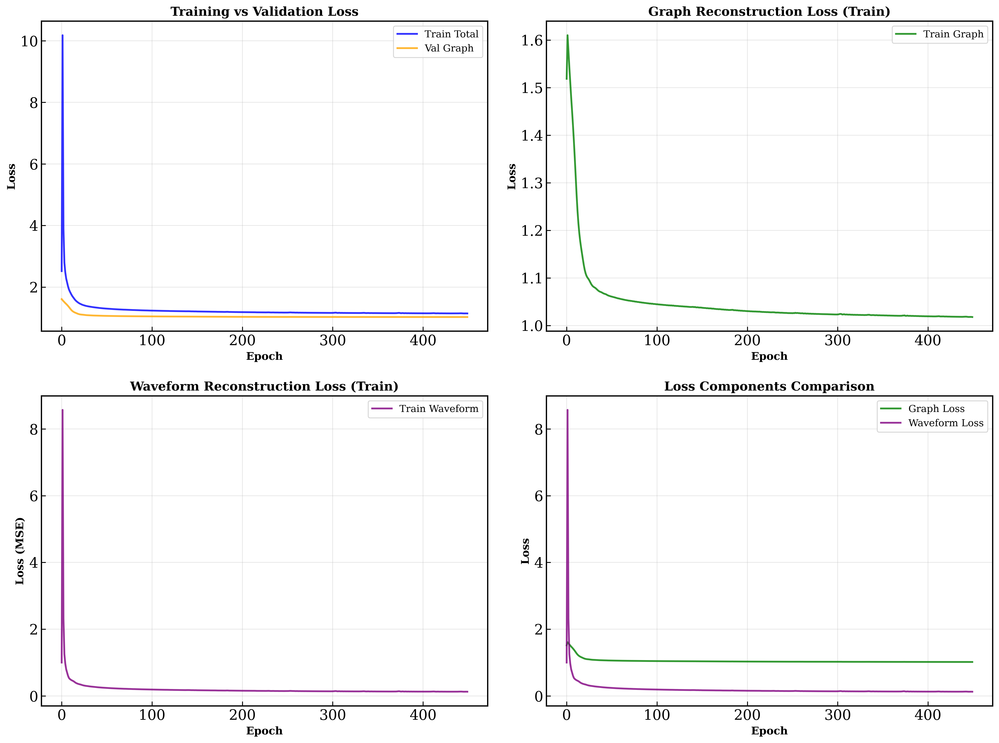

In [18]:
##############################################
# Visualize GAE Training History
##############################################

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Total Loss (Train vs Val)
axes[0, 0].plot(gae_train_losses, label='Train Total', linewidth=2, alpha=0.8, color='blue')
axes[0, 0].plot(gae_val_losses, label='Val Graph', linewidth=2, alpha=0.8, color='orange')
axes[0, 0].set_xlabel('Epoch', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Loss', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Training vs Validation Loss', fontsize=14, fontweight='bold')
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(True, alpha=0.3)

# 2. Graph Reconstruction Loss
axes[0, 1].plot(graph_losses, label='Train Graph', linewidth=2, alpha=0.8, color='green')
axes[0, 1].set_xlabel('Epoch', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Loss', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Graph Reconstruction Loss (Train)', fontsize=14, fontweight='bold')
axes[0, 1].legend(fontsize=11)
axes[0, 1].grid(True, alpha=0.3)

# 3. Waveform Reconstruction Loss
axes[1, 0].plot(waveform_losses, label='Train Waveform', linewidth=2, alpha=0.8, color='purple')
axes[1, 0].set_xlabel('Epoch', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Loss (MSE)', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Waveform Reconstruction Loss (Train)', fontsize=14, fontweight='bold')
axes[1, 0].legend(fontsize=11)
axes[1, 0].grid(True, alpha=0.3)

# 4. Loss Components Comparison
axes[1, 1].plot(graph_losses, label='Graph Loss', linewidth=2, alpha=0.8, color='green')
axes[1, 1].plot(waveform_losses, label='Waveform Loss', linewidth=2, alpha=0.8, color='purple')
axes[1, 1].set_xlabel('Epoch', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Loss', fontsize=12, fontweight='bold')
axes[1, 1].set_title('Loss Components Comparison', fontsize=14, fontweight='bold')
axes[1, 1].legend(fontsize=11)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



## Visualize Latent Space & Clustering


### t-SNE Projection (2D)


In [19]:
##############################################
# Extract Latent Representations
##############################################

from sklearn.manifold import TSNE

joint_model.eval()
with torch.no_grad():
    # Get latent representations from the full pipeline
    final_edge_index = build_knn_graph(joint_model.encoder(screened_events_tensor), k=5).to(device)
    latent_representations, reconstructed = joint_model(screened_events_tensor, final_edge_index)

# Convert to numpy for visualization
latent_np = latent_representations.cpu().numpy()

print(f"✅ Extracted latent representations")
print(f"   Shape: {latent_np.shape}")
print(f"   Mean: {latent_np.mean():.4f}")
print(f"   Std: {latent_np.std():.4f}")

✅ Extracted latent representations
   Shape: (3397, 128)
   Mean: 0.1502
   Std: 9.9863


In [ ]:
##############################################
# t-SNE Visualization
##############################################

print("🔍 Computing t-SNE projection...")
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, n_iter=1000)
latent_2d = tsne.fit_transform(latent_np)

plt.figure(figsize=(10, 8))
plt.scatter(latent_2d[:, 0], latent_2d[:, 1], s=20, alpha=0.6, c='steelblue', edgecolors='black', linewidth=0.5)
#plt.title("t-SNE Visualization of GAE Latent Space", fontsize=16, fontweight='bold')
plt.xlabel("t-SNE Component 1", fontsize=12, fontweight='bold')
plt.ylabel("t-SNE Component 2", fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("✅ t-SNE visualization complete")

## Clustering

In [21]:
##############################################
# Clustering: Discover Event Types (Enhanced)
##############################################

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler

# Standardize latent features for better clustering
scaler = StandardScaler()
latent_scaled = scaler.fit_transform(latent_np)

print("🔍 Testing different numbers of clusters with multiple metrics...\n")

# Multiple evaluation metrics
results = []
n_clusters_range = range(2, 11)

for n_clusters in n_clusters_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=SEED, n_init='auto', max_iter=300)
    labels = kmeans.fit_predict(latent_scaled)
    
    # Multiple quality metrics
    sil_score = silhouette_score(latent_scaled, labels)
    db_score = davies_bouldin_score(latent_scaled, labels)  # Lower is better
    ch_score = calinski_harabasz_score(latent_scaled, labels)  # Higher is better
    inertia = kmeans.inertia_
    
    results.append({
        'n_clusters': n_clusters,
        'silhouette': sil_score,
        'davies_bouldin': db_score,
        'calinski_harabasz': ch_score,
        'inertia': inertia
    })
    
    print(f"   n={n_clusters:2d} | Sil: {sil_score:.4f} | DB: {db_score:.4f} | CH: {ch_score:.1f} | Inertia: {inertia:.1f}")

# Find optimal k using elbow method + silhouette
silhouettes = [r['silhouette'] for r in results]
inertias = [r['inertia'] for r in results]

# Normalize metrics for combined scoring
sil_norm = (np.array(silhouettes) - min(silhouettes)) / (max(silhouettes) - min(silhouettes))
db_norm = 1 - (np.array([r['davies_bouldin'] for r in results]) - min([r['davies_bouldin'] for r in results])) / \
          (max([r['davies_bouldin'] for r in results]) - min([r['davies_bouldin'] for r in results]))

# Combined score (higher is better)
combined_scores = 0.6 * sil_norm + 0.4 * db_norm
optimal_idx = np.argmax(combined_scores)
optimal_n = n_clusters_range[optimal_idx]

print(f"\n💡 Optimal number of clusters: {optimal_n}")
print(f"   Method: Combined score (Silhouette + Davies-Bouldin)")
print(f"   Silhouette: {results[optimal_idx]['silhouette']:.4f}")
print(f"   Davies-Bouldin: {results[optimal_idx]['davies_bouldin']:.4f}")

optimal_n = 4

# Perform final clustering with optimal k
kmeans_final = KMeans(n_clusters=optimal_n, random_state=SEED, n_init='auto', max_iter=300)
cluster_labels = kmeans_final.fit_predict(latent_scaled) + 1  # 1-based labeling (C1, C2, ...)

print(f"\n📊 Cluster distribution:")
for i in range(1, optimal_n + 1):
    count = (cluster_labels == i).sum()
    print(f"   C{i}: {count:4d} events ({count/len(cluster_labels)*100:.1f}%)")

# Additional clustering quality metrics
print(f"\n✅ Final Clustering Quality:")
print(f"   Silhouette Score: {silhouette_score(latent_scaled, cluster_labels):.4f}")
print(f"   Davies-Bouldin Index: {davies_bouldin_score(latent_scaled, cluster_labels):.4f} (lower is better)")
print(f"   Calinski-Harabasz Index: {calinski_harabasz_score(latent_scaled, cluster_labels):.1f} (higher is better)")

🔍 Testing different numbers of clusters with multiple metrics...

   n= 2 | Sil: 0.1812 | DB: 2.4088 | CH: 558.8 | Inertia: 373364.2
   n= 3 | Sil: 0.2444 | DB: 1.8048 | CH: 737.2 | Inertia: 303125.6
   n= 4 | Sil: 0.2660 | DB: 1.5567 | CH: 765.7 | Inertia: 259284.0
   n= 5 | Sil: 0.3027 | DB: 1.3169 | CH: 836.8 | Inertia: 218854.4
   n= 6 | Sil: 0.3669 | DB: 1.1153 | CH: 986.4 | Inertia: 177159.0
   n= 7 | Sil: 0.3670 | DB: 1.0632 | CH: 939.6 | Inertia: 163279.2
   n= 8 | Sil: 0.4040 | DB: 1.0205 | CH: 1086.3 | Inertia: 134049.6
   n= 9 | Sil: 0.4261 | DB: 0.9181 | CH: 1222.5 | Inertia: 111872.0
   n=10 | Sil: 0.4200 | DB: 0.9427 | CH: 1185.5 | Inertia: 104771.2

💡 Optimal number of clusters: 9
   Method: Combined score (Silhouette + Davies-Bouldin)
   Silhouette: 0.4261
   Davies-Bouldin: 0.9181

📊 Cluster distribution:
   C1:  563 events (16.6%)
   C2: 1082 events (31.9%)
   C3:  687 events (20.2%)
   C4: 1065 events (31.4%)

✅ Final Clustering Quality:
   Silhouette Score: 0.2660
 

In [ ]:
# Visualize clustering metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Silhouette scores
axes[0].plot(n_clusters_range, silhouettes, marker='o', linewidth=2, markersize=8, color='steelblue')
axes[0].axvline(optimal_n, color='red', linestyle='--', alpha=0.7, label=f'Optimal k={optimal_n}')
axes[0].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Silhouette Score', fontsize=12, fontweight='bold')
axes[0].set_title('Silhouette Score vs Number of Clusters', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Elbow curve (Inertia)
axes[1].plot(n_clusters_range, inertias, marker='o', linewidth=2, markersize=8, color='darkorange')
axes[1].axvline(optimal_n, color='red', linestyle='--', alpha=0.7, label=f'Optimal k={optimal_n}')
axes[1].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Inertia', fontsize=12, fontweight='bold')
axes[1].set_title('Elbow Curve (Inertia)', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Combined score
axes[2].plot(n_clusters_range, combined_scores, marker='o', linewidth=2, markersize=8, color='green')
axes[2].axvline(optimal_n, color='red', linestyle='--', alpha=0.7, label=f'Optimal k={optimal_n}')
axes[2].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Combined Score', fontsize=12, fontweight='bold')
axes[2].set_title('Combined Quality Score', fontsize=14, fontweight='bold')
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

/tmp/zz342074/login23-g-1_511059/ipykernel_60677/983951336.py:21: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(latent_2d[mask, 0], latent_2d[mask, 1],


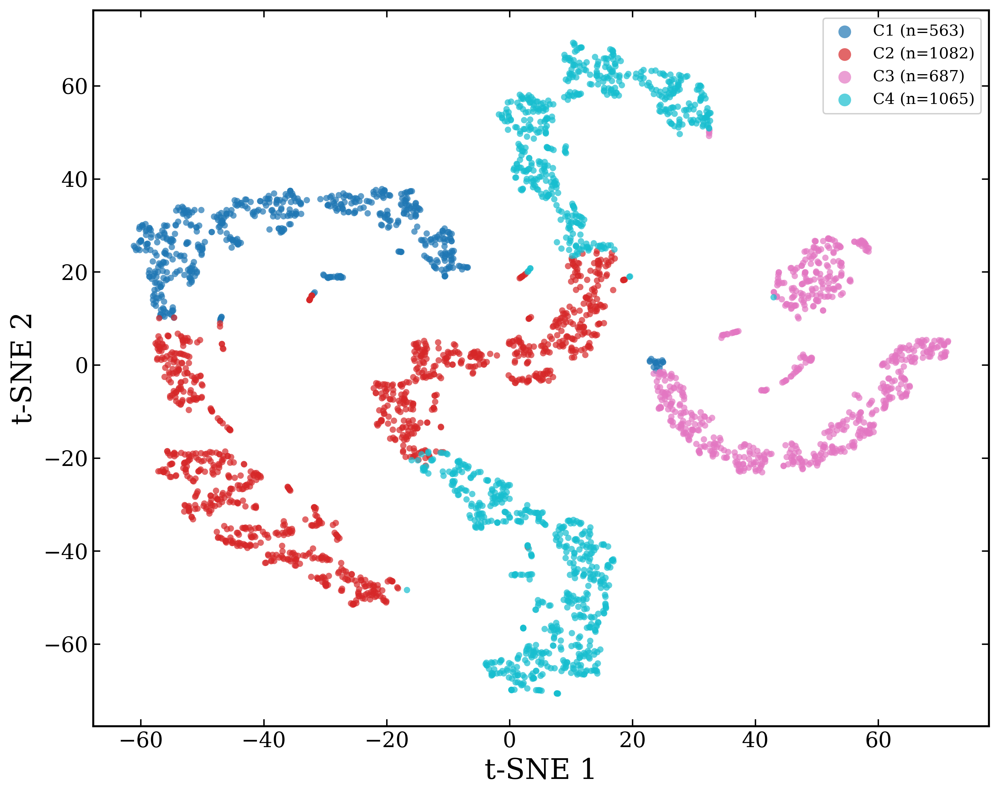

In [23]:
##############################################
# Visualize Clusters in t-SNE Space
##############################################

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 20,
    'xtick.labelsize': 15, 'ytick.labelsize': 15, 'figure.dpi': 350,
    'savefig.dpi': 350, 'font.family': 'serif', 'axes.linewidth': 1.4,
    'xtick.major.width': 1.0, 'ytick.major.width': 1.0,
    'xtick.direction': 'in', 'ytick.direction': 'in',
})

fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.tab10(np.linspace(0, 1, optimal_n))

for i in range(1, optimal_n + 1):
    mask = cluster_labels == i
    ax.scatter(latent_2d[mask, 0], latent_2d[mask, 1],
               s=20, alpha=0.7, c=colors[i - 1],
               label=f'C{i} (n={mask.sum()})',
               edgecolors='none')

ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
ax.tick_params(which='both', top=True, right=True)
ax.legend(fontsize=11, loc='best', framealpha=0.9, markerscale=2.0)

plt.tight_layout()
#plt.savefig('Figure_Clusters_tSNE.pdf', dpi=300, bbox_inches='tight')
#plt.savefig('Figure_Clusters_tSNE.png', dpi=300, bbox_inches='tight')
plt.show()

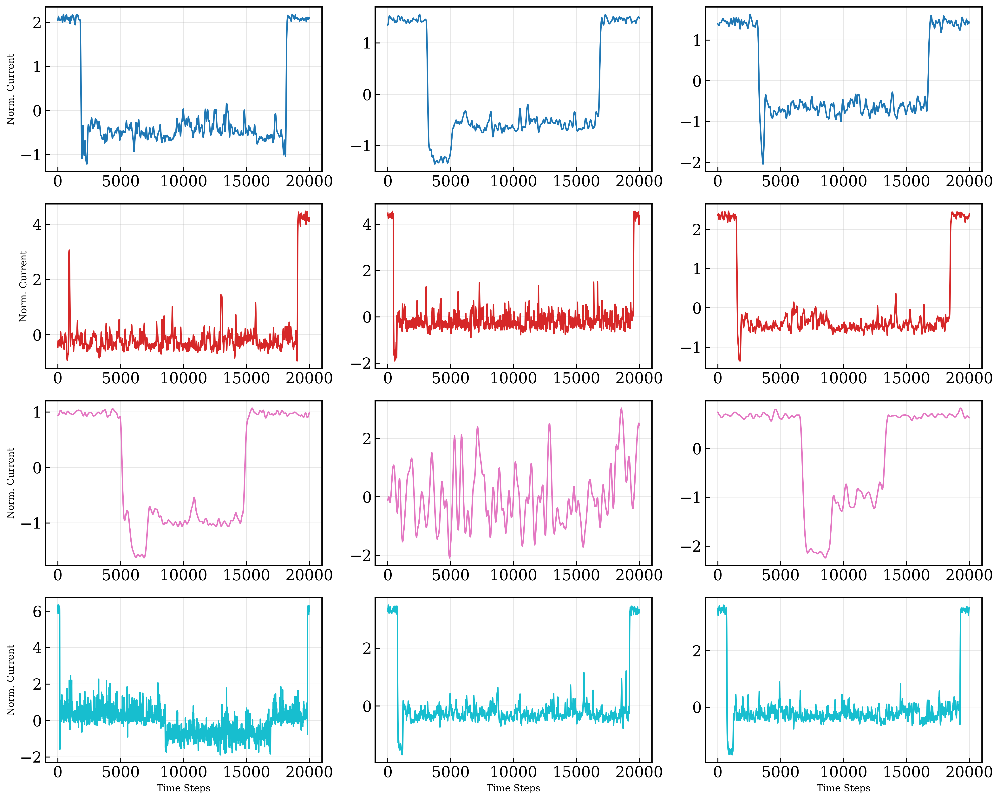

In [24]:
##############################################
# Visualize Representative Events from Each Cluster
##############################################

colors = plt.cm.tab10(np.linspace(0, 1, optimal_n))

fig, axes = plt.subplots(optimal_n, 3, figsize=(15, 3*optimal_n))
if optimal_n == 1:
    axes = axes.reshape(1, -1)

for idx_i, cluster_id in enumerate(range(1, optimal_n + 1)):
    # Get events in this cluster
    cluster_mask = cluster_labels == cluster_id
    cluster_indices = np.where(cluster_mask)[0]
    
    # Sample 3 random events from this cluster
    n_samples = min(3, len(cluster_indices))
    sample_indices = np.random.choice(cluster_indices, n_samples, replace=False)
    
    for j, idx in enumerate(sample_indices):
        axes[idx_i, j].plot(screened_events[idx], linewidth=1.5, color=colors[idx_i])
        #axes[idx_i, j].set_title(f'C{cluster_id} - Event {j+1}', fontsize=10)
        axes[idx_i, j].grid(True, alpha=0.3)
        axes[idx_i, j].tick_params(axis='both', labelsize=16)
        if j == 0:
            axes[idx_i, j].set_ylabel('Norm. Current', fontsize=10)
        if idx_i == optimal_n - 1:
            axes[idx_i, j].set_xlabel('Time Steps', fontsize=10)
    
    # Hide unused subplots
    for j in range(n_samples, 3):
        axes[idx_i, j].axis('off')

#plt.suptitle('Representative Events from Each Cluster', fontsize=20, fontweight='bold', y=1.001)
plt.tight_layout()
plt.show()

 Cluster |  Count |  Mean (ms) | Median (ms) | Min (ms) | Max (ms)
----------------------------------------------------------------------
      C1 |    563 |       1.79 |        1.80 |     0.50 |     2.54
      C2 |   1082 |       6.34 |        4.31 |     0.52 |    13.13
      C3 |    687 |       1.04 |        0.69 |     0.50 |    53.98
      C4 |   1065 |      12.10 |        7.38 |     0.54 |    53.09


/tmp/zz342074/login23-g-1_511059/ipykernel_60677/334461960.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axs[0].boxplot(cluster_duration_data, labels=[f'C{c}' for c in range(1, optimal_n + 1)],





In [25]:
# Durations for each screened event (same order as cluster_labels)
screened_durations = df_events[event_mask]['duration_ms'].values

# --- Per-cluster duration statistics ---
print(f"{'Cluster':>8} | {'Count':>6} | {'Mean (ms)':>10} | {'Median (ms)':>11} | {'Min (ms)':>8} | {'Max (ms)':>8}")
print("-" * 70)
for c in range(1, optimal_n + 1):
    mask = cluster_labels == c
    d = screened_durations[mask]
    print(f"{'C'+str(c):>8} | {mask.sum():>6} | {d.mean():>10.2f} | {np.median(d):>11.2f} | {d.min():>8.2f} | {d.max():>8.2f}")
#And to visualize it — duration distributions per cluster + t-SNE colored by duration:


import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    'font.size': 16, 'axes.titlesize': 18, 'axes.labelsize': 18,
    'xtick.labelsize': 16, 'ytick.labelsize': 16, 'figure.dpi': 650,
    'savefig.dpi': 650, 'font.family': 'serif', 'axes.linewidth': 1.8,
    'xtick.major.width': 1.3, 'ytick.major.width': 1.3,
    'xtick.direction': 'in', 'ytick.direction': 'in',
})

fig, axs = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={'wspace': 0.35})

# --- a) Box plot: horizontal (Cluster on Y, Duration on X-top) ---
cluster_duration_data = [screened_durations[cluster_labels == c] for c in range(1, optimal_n + 1)]
bp = axs[0].boxplot(cluster_duration_data, labels=[f'C{c}' for c in range(1, optimal_n + 1)],
                     vert=False, patch_artist=True, showfliers=False,
                     medianprops=dict(color='black', linewidth=1.5))
colors = plt.cm.tab10(np.linspace(0, 1, optimal_n))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axs[0].set_ylabel('Cluster')
axs[0].set_xlabel('Duration (ms)')
axs[0].xaxis.set_label_position('top')
axs[0].xaxis.tick_top()
axs[0].tick_params(which='both', bottom=True, right=True)

# --- b) t-SNE: swap axes (t-SNE 1 on Y, t-SNE 2 on X-top) ---
sc = axs[1].scatter(latent_2d[:, 1], latent_2d[:, 0],
                    c=screened_durations, cmap='plasma', s=15, alpha=0.7, edgecolors='none')
cbar = fig.colorbar(sc, ax=axs[1], fraction=0.046, pad=0.12, orientation='horizontal', location='bottom')
cbar.set_label('Duration (ms)', fontsize=15)
axs[1].set_xlabel('t-SNE 2')
axs[1].set_ylabel('t-SNE 1')
axs[1].xaxis.set_label_position('top')
axs[1].xaxis.tick_top()
axs[1].tick_params(which='both', bottom=True, right=True)

# --- c) Histogram: horizontal (Duration on Y, Distribution on X-top) ---
median_duration = np.median(screened_durations)
for idx_i, c in enumerate(range(1, optimal_n + 1)):
    d = screened_durations[cluster_labels == c]
    axs[2].hist(d, bins=30, alpha=0.5, label=f'C{c}', color=colors[idx_i],
                edgecolor='none', orientation='horizontal')
#axs[2].axhline(median_duration, color='black', linestyle='--', linewidth=1.2, label=f'Median ({median_duration:.1f} ms)')
axs[2].set_ylabel('Duration (ms)')
axs[2].set_xlabel('Distribution')
axs[2].xaxis.set_label_position('top')
axs[2].xaxis.tick_top()
axs[2].legend(fontsize=9, framealpha=0.9)
axs[2].tick_params(which='both', bottom=True, right=True)

#plt.savefig('cluster_duration_analysis.pdf', bbox_inches='tight', pad_inches=0.1)
#plt.savefig('cluster_duration_analysis.png', bbox_inches='tight', pad_inches=0.1)
plt.show()


 Cluster |  Count |  Mean (pA) | Median (pA) |  Min (pA) |  Max (pA)
------------------------------------------------------------------------
      C1 |    563 |     102.08 |      112.17 |    -29.53 |    147.18
      C2 |   1082 |     127.99 |      133.25 |    -27.72 |    169.84
      C3 |    687 |      40.76 |       41.25 |    -79.60 |    156.30
      C4 |   1065 |     135.00 |      137.93 |    -29.29 |    185.79


/tmp/zz342074/login23-g-1_511059/ipykernel_60677/1668812515.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axs[0].boxplot(cluster_depth_data, labels=[f'C{c}' for c in range(1, optimal_n + 1)],





In [26]:
##############################################
# Blockade Depth Analysis by Cluster
##############################################

import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    'font.size': 16, 'axes.titlesize': 16, 'axes.labelsize': 18,
    'xtick.labelsize': 14, 'ytick.labelsize': 12, 'figure.dpi': 650,
    'savefig.dpi': 650, 'font.family': 'serif', 'axes.linewidth': 1.5,
    'xtick.major.width': 1.3, 'ytick.major.width': 1.3,
    'xtick.direction': 'in', 'ytick.direction': 'in',
})

screened_df = df_events[event_mask].reset_index(drop=True)
screened_depths = (screened_df['baseline'] - screened_df['mean_current']).values

print(f"{'Cluster':>8} | {'Count':>6} | {'Mean (pA)':>10} | {'Median (pA)':>11} | {'Min (pA)':>9} | {'Max (pA)':>9}")
print("-" * 72)
for c in range(1, optimal_n + 1):
    mask = cluster_labels == c
    d = screened_depths[mask]
    print(f"{'C'+str(c):>8} | {mask.sum():>6} | {d.mean():>10.2f} | {np.median(d):>11.2f} | {d.min():>9.2f} | {d.max():>9.2f}")

fig, axs = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={'wspace': 0.35})

# --- a) Box plot: horizontal (Cluster on Y, Depth on X-top) ---
colors = plt.cm.tab10(np.linspace(0, 1, optimal_n))
cluster_depth_data = [screened_depths[cluster_labels == c] for c in range(1, optimal_n + 1)]
bp = axs[0].boxplot(cluster_depth_data, labels=[f'C{c}' for c in range(1, optimal_n + 1)],
                     vert=False, patch_artist=True, showfliers=False,
                     medianprops=dict(color='black', linewidth=1.5))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axs[0].set_ylabel('Cluster')
axs[0].set_xlabel('Blockade Depth (pA)')
axs[0].xaxis.set_label_position('top')
axs[0].xaxis.tick_top()
axs[0].tick_params(which='both', bottom=True, right=True)

# --- b) t-SNE: swap axes (t-SNE 1 on Y, t-SNE 2 on X-top) ---
sc = axs[1].scatter(latent_2d[:, 1], latent_2d[:, 0],
                    c=screened_depths, cmap='plasma', s=15, alpha=0.7, edgecolors='none')
cbar = fig.colorbar(sc, ax=axs[1], fraction=0.046, pad=0.12, orientation='horizontal', location='bottom')
cbar.set_label('Blockade Depth (pA)', fontsize=15)
axs[1].set_xlabel('t-SNE 2')
axs[1].set_ylabel('t-SNE 1')
axs[1].xaxis.set_label_position('top')
axs[1].xaxis.tick_top()
axs[1].tick_params(which='both', bottom=True, right=True)

# --- c) Histogram: horizontal (Depth on Y, Count on X-top) ---
median_depth = np.median(screened_depths)
for idx_i, c in enumerate(range(1, optimal_n + 1)):
    d = screened_depths[cluster_labels == c]
    axs[2].hist(d, bins=30, alpha=0.5, label=f'C{c}', color=colors[idx_i],
                edgecolor='none', orientation='horizontal')
#axs[2].axhline(median_depth, color='black', linestyle='--', linewidth=1.2, label=f'Median ({median_depth:.1f} pA)')
axs[2].invert_xaxis()
axs[2].yaxis.set_label_position('right')
axs[2].yaxis.tick_right()
axs[2].set_ylabel('Blockade Depth (pA)')
axs[2].set_xlabel('Count')
axs[2].xaxis.set_label_position('top')
axs[2].xaxis.tick_top()
axs[2].legend(fontsize=9, framealpha=0.9)
axs[2].tick_params(which='both', bottom=True, left=True)


plt.show()


### 🖼️ Original vs Reconstructed (Examples)

We visually compare a handful of randomly selected events:
- Overlay original and reconstructed traces to spot biases.
- Titles include per-event MSE and correlation for quick reference.

### 📉 Reconstruction Metrics

We quantify reconstruction quality for each event:
- MSE captures absolute amplitude error.
- Pearson correlation captures shape similarity independent of scale.
- Reports both global stats and per-cluster breakdowns.

In [ ]:
##############################################
# Compute Reconstruction Metrics
##############################################

# Convert reconstructed waveforms to numpy
reconstructed_np = reconstructed.cpu().detach().numpy().squeeze()
original_np = screened_events

# Compute MSE for each event
mse_per_event = np.mean((original_np - reconstructed_np)**2, axis=1)

# Compute correlation for each event
correlations = []
for i in range(len(original_np)):
    corr = np.corrcoef(original_np[i], reconstructed_np[i])[0, 1]
    correlations.append(corr)
correlations = np.array(correlations)

print("="*70)
print("RECONSTRUCTION QUALITY METRICS")
print("="*70)
print(f"\n📊 Overall Statistics:")
print(f"   Mean MSE: {mse_per_event.mean():.6f} ± {mse_per_event.std():.6f}")
print(f"   Median MSE: {np.median(mse_per_event):.6f}")
print(f"   Mean Correlation: {correlations.mean():.4f} ± {correlations.std():.4f}")
print(f"   Median Correlation: {np.median(correlations):.4f}")

print(f"\n📊 Per-Cluster Statistics:")
for cluster_id in range(optimal_n):
    cluster_mask = cluster_labels == cluster_id
    cluster_mse = mse_per_event[cluster_mask]
    cluster_corr = correlations[cluster_mask]
    print(f"   Cluster {cluster_id}: MSE={cluster_mse.mean():.6f}, Corr={cluster_corr.mean():.4f}")

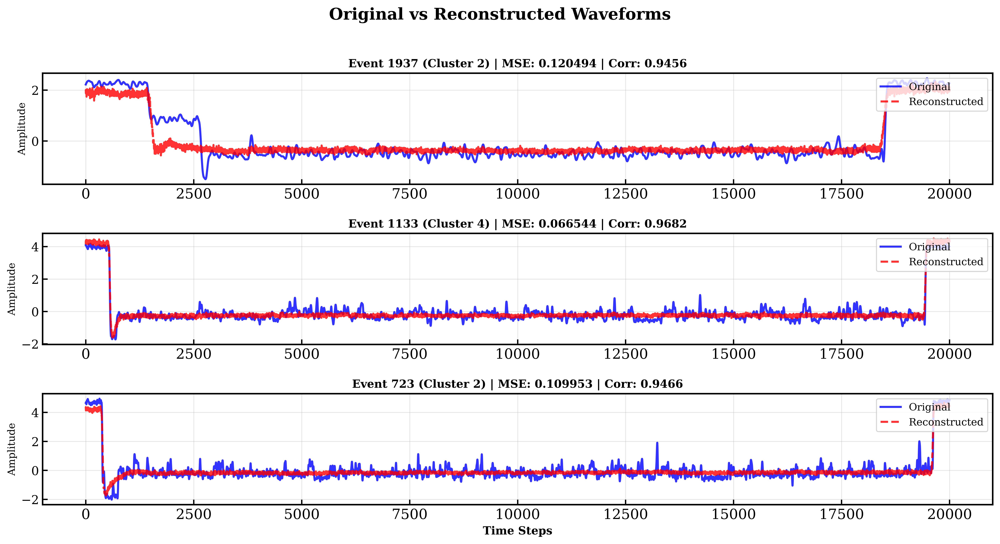

In [ ]:
##############################################
# Visualize Reconstruction Examples
##############################################

n_samples = 3
sample_indices = np.random.choice(len(original_np), n_samples, replace=False)

fig, axes = plt.subplots(n_samples, 1, figsize=(14, 2.5*n_samples))

for i, idx in enumerate(sample_indices):
    axes[i].plot(original_np[idx], label='Original', linewidth=2, alpha=0.8, color='blue')
    axes[i].plot(reconstructed_np[idx], label='Reconstructed', linewidth=2, alpha=0.8, 
                linestyle='--', color='red')
    
    cluster_id = cluster_labels[idx]
    mse = mse_per_event[idx]
    corr = correlations[idx]
    
    axes[i].set_title(f'Event {idx} (Cluster {cluster_id}) | MSE: {mse:.6f} | Corr: {corr:.4f}', 
                     fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Amplitude', fontsize=10)
    axes[i].legend(fontsize=10, loc='upper right')
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel('Time Steps', fontsize=11, fontweight='bold')
plt.suptitle('Original vs Reconstructed Waveforms', fontsize=16, fontweight='bold', y=1.001)
plt.tight_layout()
plt.show()

### 🕹️ Interactive Waveform Viewer

Navigate through reconstructions to inspect individual events:
- Buttons: Previous / Next / Random.
- Title shows cluster, MSE, correlation for the current event.
- Useful for auditing edge cases and understanding reconstruction failures.

Note: The interactive viewer is optional and may require a GUI backend.

In [29]:
##############################################
# Visualize Original vs Reconstructed Waveforms (Individual Events)
##############################################

import matplotlib.pyplot as plt
from matplotlib.widgets import Button
import numpy as np

# Prepare all reconstructions
joint_model.eval()
with torch.no_grad():
    final_edge_index = build_knn_graph(joint_model.encoder(screened_events_tensor), k=5).to(device)
    _, all_reconstructed = joint_model(screened_events_tensor, final_edge_index)

# Convert to numpy
all_reconstructed_np = all_reconstructed.cpu().detach().numpy().squeeze()
original_np = screened_events

# Create interactive visualization
class WaveformViewer:
    def __init__(self, original_data, reconstructed_data, cluster_labels):
        self.original = original_data
        self.reconstructed = reconstructed_data
        self.clusters = cluster_labels
        self.current_idx = 0
        self.n_samples = len(original_data)
        
        # Create figure
        self.fig, self.ax = plt.subplots(figsize=(14, 6))
        plt.subplots_adjust(bottom=0.2)
        
        # Create navigation buttons
        ax_prev = plt.axes([0.3, 0.05, 0.1, 0.05])
        ax_next = plt.axes([0.6, 0.05, 0.1, 0.05])
        ax_random = plt.axes([0.45, 0.05, 0.1, 0.05])
        
        self.btn_prev = Button(ax_prev, 'Previous')
        self.btn_next = Button(ax_next, 'Next')
        self.btn_random = Button(ax_random, 'Random')
        
        self.btn_prev.on_clicked(self.prev_event)
        self.btn_next.on_clicked(self.next_event)
        self.btn_random.on_clicked(self.random_event)
        
        # Initial plot
        self.update_plot()
        
    def update_plot(self):
        self.ax.clear()
        
        idx = self.current_idx
        orig = self.original[idx]
        recon = self.reconstructed[idx]
        cluster_id = self.clusters[idx]
        
        # Compute metrics
        mse = np.mean((orig - recon)**2)
        corr = np.corrcoef(orig, recon)[0, 1]
        
        # Plot
        time_steps = np.arange(len(orig))
        self.ax.plot(time_steps, orig, label='Original', linewidth=2, alpha=0.8, color='blue')
        self.ax.plot(time_steps, recon, label='Reconstructed', linewidth=2, alpha=0.8, 
                    linestyle='--', color='red')
        
        # Title with metrics
        self.ax.set_title(
            f'Event #{idx} | Cluster {cluster_id} | MSE: {mse:.6f} | Correlation: {corr:.4f}\n'
            f'({idx+1}/{self.n_samples})',
            fontsize=12, fontweight='bold'
        )
        
        self.ax.set_xlabel('Time Steps', fontsize=11, fontweight='bold')
        self.ax.set_ylabel('Normalized Amplitude', fontsize=11, fontweight='bold')
        self.ax.legend(fontsize=11, loc='upper right')
        self.ax.grid(True, alpha=0.3)
        
        plt.draw()
        
    def next_event(self, event):
        self.current_idx = (self.current_idx + 1) % self.n_samples
        self.update_plot()
        
    def prev_event(self, event):
        self.current_idx = (self.current_idx - 1) % self.n_samples
        self.update_plot()
        
    def random_event(self, event):
        self.current_idx = np.random.randint(0, self.n_samples)
        self.update_plot()

# Create interactive viewer
#print("="*70)
#print("INTERACTIVE WAVEFORM VIEWER")
#print("="*70)
#print("\n📊 Controls:")
#print("   • Click 'Next' to view next event")
#print("   • Click 'Previous' to view previous event")
#print("   • Click 'Random' to view a random event")
#print("   • Close window when done\n")

#viewer = WaveformViewer(original_np, all_reconstructed_np, cluster_labels)
#plt.show()

##############################################
# View Specific Events by Index
##############################################

def plot_specific_events(original_data, reconstructed_data, cluster_labels, event_indices):
    """
    Plot specific events by their indices
    
    Args:
        event_indices: list of event indices to visualize
    """
    n_events = len(event_indices)
    fig, axes = plt.subplots(n_events, 1, figsize=(14, 3*n_events))
    
    if n_events == 1:
        axes = [axes]
    
    for i, idx in enumerate(event_indices):
        if idx >= len(original_data):
            print(f"⚠️ Warning: Event #{idx} does not exist (max: {len(original_data)-1})")
            continue
            
        orig = original_data[idx]
        recon = reconstructed_data[idx]
        cluster_id = cluster_labels[idx]
        
        # Compute metrics
        mse = np.mean((orig - recon)**2)
        corr = np.corrcoef(orig, recon)[0, 1]
        
        # Plot
        time_steps = np.arange(len(orig))
        axes[i].plot(time_steps, orig, label='Original', linewidth=2, alpha=0.8, color='blue')
        axes[i].plot(time_steps, recon, label='Reconstructed', linewidth=2, alpha=0.8, 
                    linestyle='--', color='red')
        
        # Title
        axes[i].set_title(
            f'Event #{idx} | Cluster {cluster_id} | MSE: {mse:.6f} | Correlation: {corr:.4f}',
            fontsize=12, fontweight='bold'
        )
        
        axes[i].set_xlabel('Time Steps', fontsize=11, fontweight='bold')
        axes[i].set_ylabel('Normalized Amplitude', fontsize=11, fontweight='bold')
        axes[i].legend(fontsize=11, loc='upper right')
        axes[i].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


### 🔎 View Specific Events by Index

Utility function to plot chosen indices:
- Handy for bookmarking interesting or problematic events.
- Works with cluster labels to add context to each example.


📊 Viewing specific events...


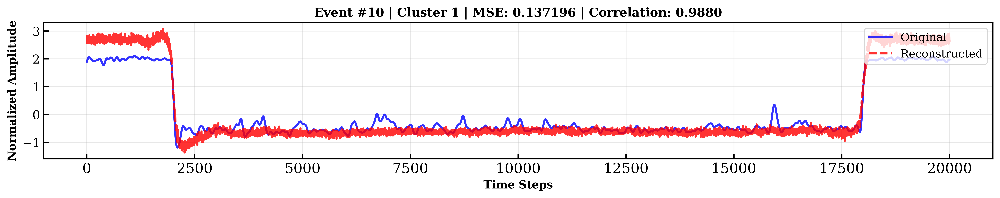

In [30]:

# Example usage: View specific events
print("\n📊 Viewing specific events...")
plot_specific_events(original_np, all_reconstructed_np, cluster_labels, 
                    event_indices=[10])


## 💾 Saving Models and Artifacts

We persist the key outputs for later inference and analysis:
- `fast_screener.pth`: Stage 1 CNN weights.
- `gae_model.pth`: Best Stage 2 GAE checkpoint (by validation loss).
- `cluster_labels.npy`, `latent_representations.npy`: Clustering results for downstream tasks.

In [32]:
##############################################
# Save Models and Results
##############################################

# Save the cluster labels
np.save('cluster_labels.npy', cluster_labels)
np.save('latent_representations.npy', latent_np)


In [ ]:
##############################################
# Save Training Latent Space with Metadata
##############################################

import pickle

# Compute cluster centroids
cluster_centroids = np.zeros((optimal_n, latent_np.shape[1]))
for i in range(optimal_n):
    cluster_mask = cluster_labels == i
    cluster_centroids[i] = latent_np[cluster_mask].mean(axis=0)

print(f"✅ Cluster centroids computed: {cluster_centroids.shape}")

# Save comprehensive training data
training_latent_data = {
    'latent_vectors': latent_np,
    'cluster_labels': cluster_labels,
    'cluster_centroids': cluster_centroids,
    'screened_events': screened_events,
    'event_mask': event_mask,
    'metadata': df_events[event_mask].reset_index(drop=True),
    'tsne_2d': latent_2d,  # Save t-SNE projection for consistent visualization
    'optimal_n_clusters': optimal_n,
    # Additional useful info
    'silhouette_scores': silhouettes,
    'clustering_results': results,  # All clustering metrics
    'mse_per_event': mse_per_event,
    'correlations': correlations
}

# Save to pickle
with open('training_latent_space.pkl', 'wb') as f:
    pickle.dump(training_latent_data, f)

print("✅ Training latent space saved to: training_latent_space.pkl")
print(f"\n📦 Saved data includes:")
print(f"   • Latent vectors: {latent_np.shape}")
print(f"   • Cluster labels: {len(cluster_labels)} events")
print(f"   • Cluster centroids: {cluster_centroids.shape}")
print(f"   • t-SNE 2D projection: {latent_2d.shape}")
print(f"   • Event metadata: {len(training_latent_data['metadata'])} rows")
print(f"   • Reconstruction metrics (MSE, correlation)")
print(f"   • Complete clustering results with all metrics")

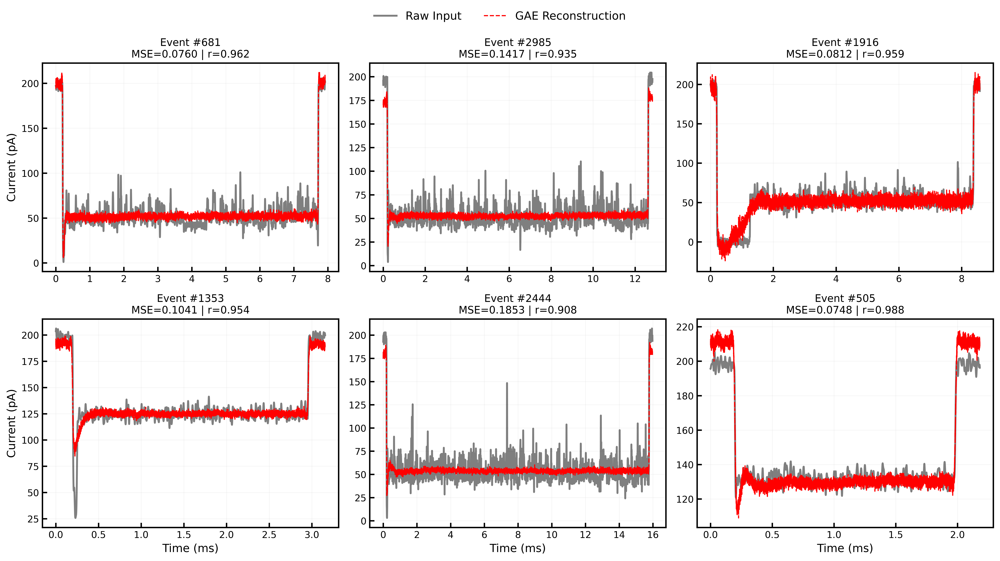

In [35]:

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap

# Set publication-quality style
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans'],
    'font.size': 10,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 16,
    'figure.dpi': 600,  # High resolution for print
    'axes.linewidth': 1.5,
    'xtick.major.width': 1.5,
    'ytick.major.width': 1.5,
    'lines.linewidth': 2,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# Define a color palette suitable for scientific publications (colorblind friendly)
sci_palette = sns.color_palette("deep", 8)
sns.set_palette(sci_palette)

# Figure 2: Reconstruction Fidelity 
import numpy as np
import matplotlib.pyplot as plt
import torch

# Get screened event normalization params
screened_df = df_events[event_mask].reset_index(drop=True)

# Create a 2x3 grid for 6 figures
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

# Select 6 random events to show
indices_to_show = np.random.choice(len(latent_np), 6, replace=False)

for i, idx in enumerate(indices_to_show):
    ax = axes[i]
    
    # Get original and reconstructed (z-score normalized)
    orig = train_data.x[idx].cpu().numpy().flatten()
    
    latent_vec = torch.tensor(latent_np[idx], dtype=torch.float32).unsqueeze(0).to(device)
    with torch.no_grad():
        recon = decoder(latent_vec).cpu().numpy().flatten()
    
    # Reverse z-score to get real current (pA)
    wf_mean = screened_df.iloc[idx]['wf_mean']
    wf_std = screened_df.iloc[idx]['wf_std']
    orig_pA = orig * wf_std + wf_mean
    recon_pA = recon * wf_std + wf_mean
    
    # Calculate metrics (on normalized data)
    mse = np.mean((orig - recon)**2)
    corr = np.corrcoef(orig, recon)[0, 1]
    
    # Real time axis from actual event duration
    duration_ms = screened_durations[idx]
    t = np.linspace(0, duration_ms, len(orig))
    
    # Plot in real scale
    l1, = ax.plot(t, orig_pA, 'k-', alpha=0.5, label='Raw Input', lw=2)
    l2, = ax.plot(t, recon_pA, 'r--', label='GAE Recon', lw=1.2)
    
    ax.set_title(f'Event #{idx}\nMSE={mse:.4f} | r={corr:.3f}', fontsize=11)
    
    # Only set labels on outer edges
    if i >= 3:
        ax.set_xlabel('Time (ms)')
    if i % 3 == 0:
        ax.set_ylabel('Current (pA)')
        
    ax.grid(True, alpha=0.1)

# Common legend at top
fig.legend([l1, l2], ['Raw Input', 'GAE Reconstruction'], 
           loc='upper center', bbox_to_anchor=(0.5, 1.05), 
           ncol=2, frameon=False, fontsize=12)

plt.tight_layout()
plt.show()